Loaded dataset with 3561 rows across 3 samples: ['KPMP057', '3729', '3811']
Target metrics (12): ['% Sterols', '% Cardiolipins', '% Phospholipids', '% Lysophospholipids', '% Diglycerides', '% Triglycerides', '% Sphingolipids', '% SFA', '% PUFA', '% Background', 'Redox Ratio Mean', 'SRS Unmatched %']


% Sterols           % Cardiolipins           % Phospholipids  \
               mean       std           mean       std            mean   
Sample ID                                                                
3729       0.025926  0.224553       0.049846  0.316081        0.010031   
3811       0.063595  0.140468       0.060641  0.134534        0.009765   
KPMP057    2.190929  3.321157       0.270601  0.420793        3.218470   

                    % Lysophospholipids           % Diglycerides           \
                std                mean       std           mean      std   
Sample ID                                                                   
3729       0.063206            0.000309  0.007857       0.000000  0.00000   
3811       0.048004            0.000050  0.002238       0.000000  0.00000   
KPMP057    4.909578            0.514754  1.158080       0.793224  1.49128   

           ...     % SFA             % PUFA           % Background             \
           ...      mean      std      mean       std         mean        std   
Sample ID  ...                                                                  
3729       ...  0.000000  0.00000  0.060494  0.212327     0.935802   3.369375   
3811       ...  0.000000  0.00000  0.260541  0.364391    12.886830  16.179070   
KPMP057    ...  0.065792  0.21538  0.129071  0.178575     5.718689   8.051188   

          Redox Ratio Mean           SRS Unmatched %             
                      mean       std            mean        std  
Sample ID                                                        
3729              0.534798  0.005359       98.920216   3.921605  
3811              0.542946  0.008977       86.718077  16.413843  
KPMP057           0.554100  0.012126       84.686448  16.040503  

[3 rows x 24 columns]

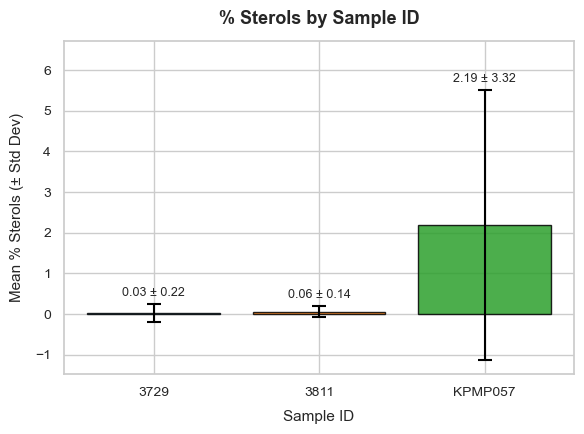

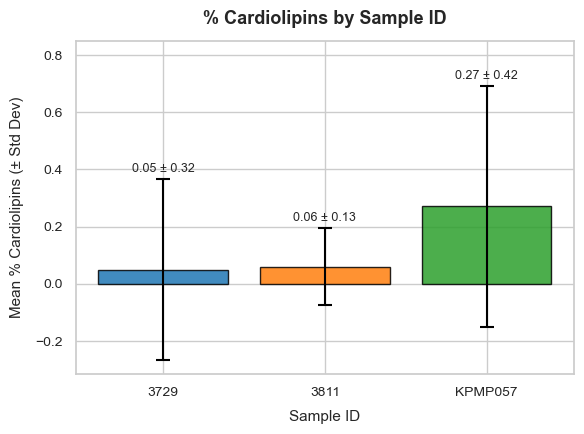

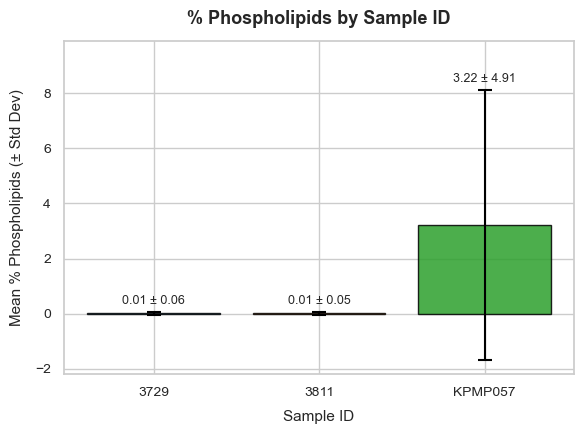

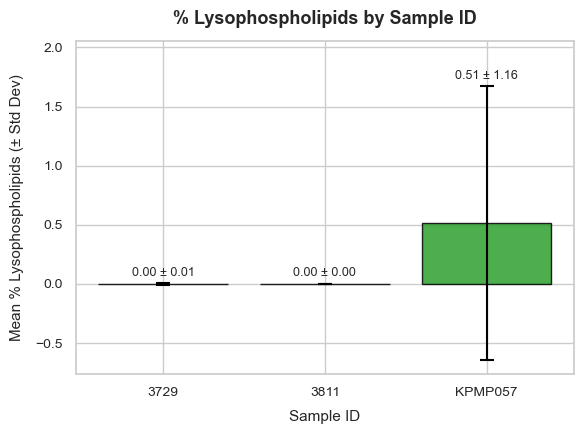

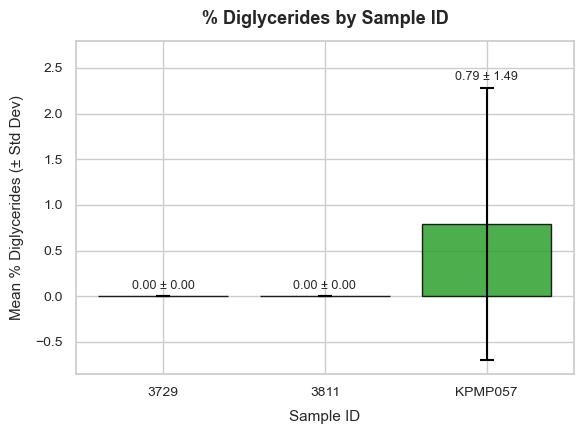

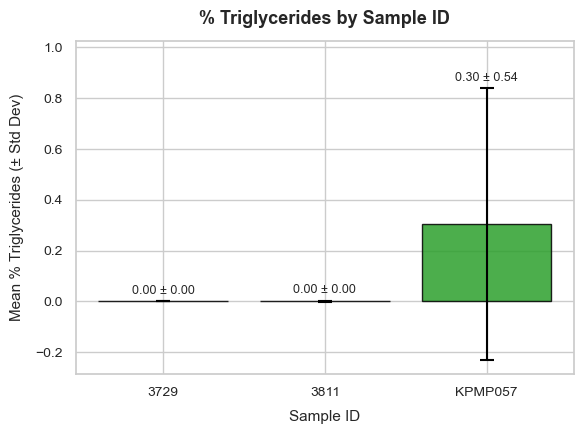

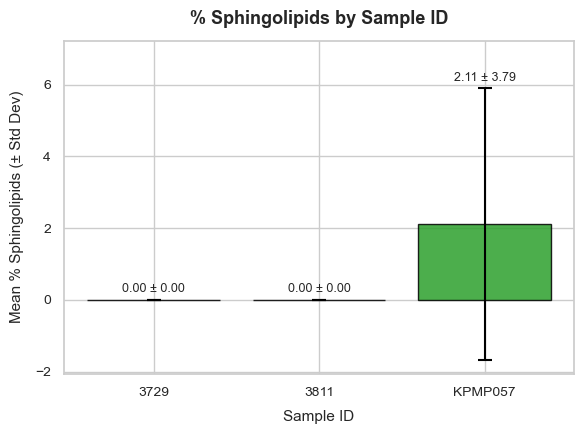

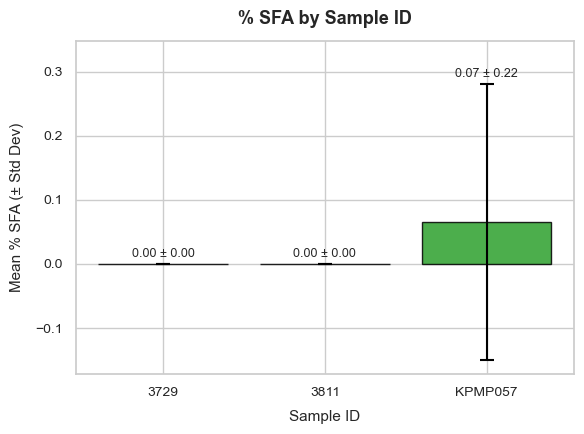

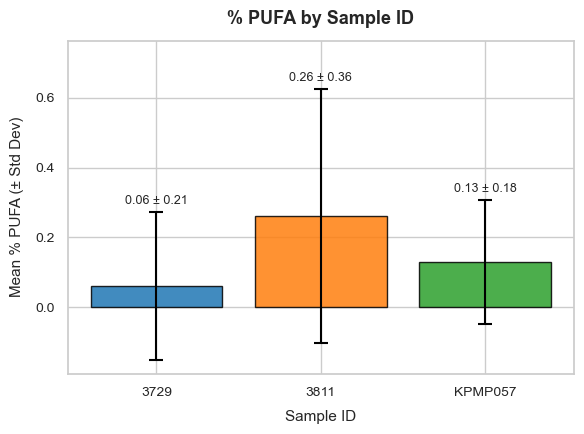

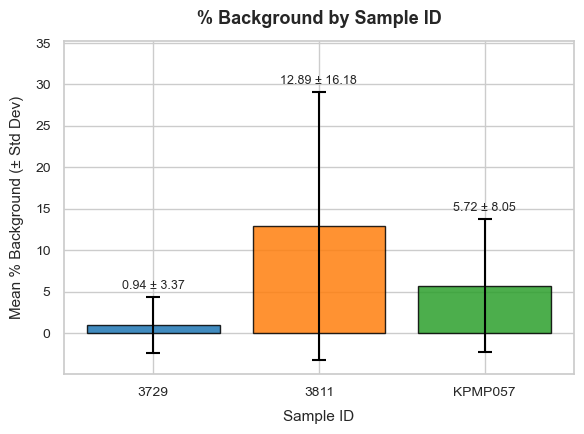

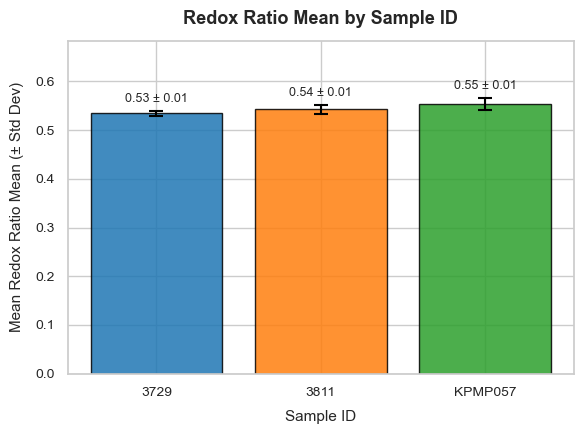

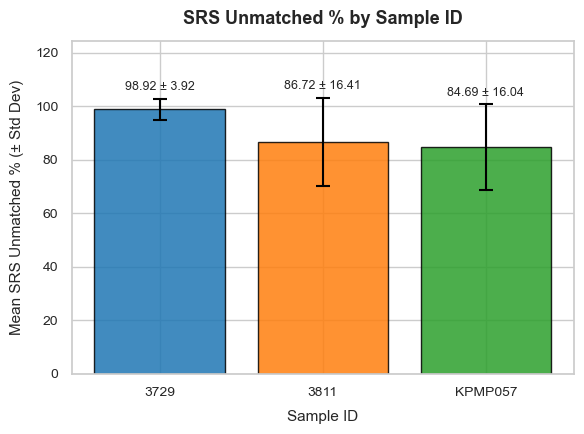

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Load the ROI metrics dataset
csv_path = "/Users/jorgevillazon/Downloads/metadata/Xenium-round2-roi_metrics.csv"
df = pd.read_csv(csv_path)

# 2. Identify % molecule columns and Redox Ratio column
molecule_pct_cols = [col for col in df.columns if col.startswith('%')]
redox_cols = [col for col in ['Redox Ratio Mean', 'Redox Ratio', 'SRS Unmatched %'] if col in df.columns]
target_cols = molecule_pct_cols + redox_cols

print(f"Loaded dataset with {len(df)} rows across {df['Sample ID'].nunique()} samples: {df['Sample ID'].unique().tolist()}")
print(f"Target metrics ({len(target_cols)}): {target_cols}")

# 3. Group by Sample ID and compute mean & standard deviation across ROIs
grouped = df.groupby('Sample ID')[target_cols].agg(['mean', 'std'])
display(grouped)

# 4. Plot separate bar plots with standard deviation error bars
sns.set_theme(style="whitegrid")
palette = sns.color_palette("tab10", n_colors=len(grouped))

for col in target_cols:
    fig, ax = plt.subplots(figsize=(6, 4.5))
    
    means = grouped[col]['mean']
    stds = grouped[col]['std']
    samples = means.index.astype(str)
    
    bars = ax.bar(
        samples, 
        means, 
        yerr=stds, 
        capsize=5, 
        color=palette, 
        edgecolor='black', 
        alpha=0.85,
        error_kw={'elinewidth': 1.5, 'ecolor': 'black', 'capthick': 1.5}
    )
    
    # Add value labels above error bars
    for bar, mean_val, std_val in zip(bars, means, stds):
        y_pos = mean_val + (std_val if not np.isnan(std_val) else 0)
        ax.text(
            bar.get_x() + bar.get_width() / 2, 
            y_pos + 0.02 * (ax.get_ylim()[1] if ax.get_ylim()[1] != 0 else 1),
            f"{mean_val:.2f} ± {std_val:.2f}",
            ha='center', va='bottom', fontsize=9, fontweight='medium'
        )
    
    ax.set_title(f"{col} by Sample ID", fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel("Sample ID", fontsize=11, labelpad=8)
    ax.set_ylabel(f"Mean {col} (± Std Dev)", fontsize=11, labelpad=8)
    ax.tick_params(axis='both', which='major', labelsize=10)
    
    # Adjust y-limit to ensure annotations fit comfortably
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(min(0, ymin), ymax * 1.15 if ymax > 0 else 1.0)
    
    plt.tight_layout()
    plt.savefig(rf"/Users/jorgevillazon/Downloads/metadata/{col}.png", transparent=True, dpi=300)
    plt.show()
